In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


In [2]:
# ============================================
# 1. IMPORT LIBRARIES
# ============================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plotting style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================
# 2. FIND DATA FILES
# ============================================

for path in Path("/kaggle/input").rglob("*"):
    print(path)

/kaggle/input/competitions
/kaggle/input/competitions/vehicle-type-classification
/kaggle/input/competitions/vehicle-type-classification/vehicle_train_10000.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_test.csv
/kaggle/input/competitions/vehicle-type-classification/vehicle_sample_submission.csv


In [4]:
# ============================================
# 3. LOAD DATA
# ============================================

DATA_PATH = "/kaggle/input/competitions/vehicle-type-classification"

train_path = f"{DATA_PATH}/vehicle_train_10000.csv"
test_path = f"{DATA_PATH}/vehicle_test.csv"
sample_path = f"{DATA_PATH}/vehicle_sample_submission.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission = pd.read_csv(sample_path)

print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

Training data shape: (10000, 22)
Test data shape: (2500, 21)
Sample submission shape: (2500, 2)


In [5]:
# ============================================
# 4. FIRST LOOK AT THE DATA
# ============================================

print("TRAINING DATA")
display(train_df.head())

print("\nTEST DATA")
display(test_df.head())

print("\nSAMPLE SUBMISSION")
display(sample_submission.head())

TRAINING DATA


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1



TEST DATA


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh
0,10001,2.17,279.0,1632.0,2752.0,4625.0,1805.0,1695.0,59.0,12.47,17.40,6.0,355.0,183.0,5.98,576.0,8.63,41.0,234.0,0.31,65.0
1,10002,1.61,189.0,1387.0,2618.0,4440.0,1766.0,1410.0,46.0,14.13,18.19,5.0,267.0,113.0,4.72,244.0,8.73,36.0,187.0,0.27,66.0
2,10003,3.00,375.0,2035.0,2990.0,5185.0,2016.0,1614.0,83.0,8.77,13.52,7.0,505.0,206.0,6.22,683.0,6.06,52.0,295.0,0.37,70.0
3,10004,2.45,316.0,1169.0,2543.0,4272.0,1698.0,1338.0,35.0,13.29,15.67,6.0,451.0,110.0,5.74,212.0,5.05,29.0,254.0,0.27,79.0
4,10005,3.08,321.0,2262.0,3063.0,5358.0,2050.0,1509.0,83.0,8.69,13.75,6.0,481.0,149.0,6.48,586.0,6.94,55.0,306.0,0.37,59.0



SAMPLE SUBMISSION


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,0
3,10004,0
4,10005,0


In [6]:
# ============================================
# 5. DATASET DIMENSIONS
# ============================================

print("Training dataset:")
print(f"Rows    : {train_df.shape[0]:,}")
print(f"Columns : {train_df.shape[1]}")

print("\nTest dataset:")
print(f"Rows    : {test_df.shape[0]:,}")
print(f"Columns : {test_df.shape[1]}")

Training dataset:
Rows    : 10,000
Columns : 22

Test dataset:
Rows    : 2,500
Columns : 21


In [7]:
# ============================================
# 6. COLUMN INFORMATION
# ============================================

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   vehicle_id                    10000 non-null  int64  
 1   engine_displacement_l         10000 non-null  float64
 2   horsepower_hp                 10000 non-null  float64
 3   vehicle_weight_kg             10000 non-null  float64
 4   wheelbase_mm                  10000 non-null  float64
 5   vehicle_length_mm             10000 non-null  float64
 6   vehicle_width_mm              10000 non-null  float64
 7   vehicle_height_mm             10000 non-null  float64
 8   fuel_tank_capacity_l          10000 non-null  float64
 9   city_fuel_efficiency_kmpl     10000 non-null  float64
 10  highway_fuel_efficiency_kmpl  10000 non-null  float64
 11  engine_cylinders              10000 non-null  float64
 12  torque_nm                     10000 non-null  float64
 13  gr

In [8]:
print("\nColumn names:")
for i, column in enumerate(train_df.columns, start=1):
    print(f"{i:2}. {column}")


Column names:
 1. vehicle_id
 2. engine_displacement_l
 3. horsepower_hp
 4. vehicle_weight_kg
 5. wheelbase_mm
 6. vehicle_length_mm
 7. vehicle_width_mm
 8. vehicle_height_mm
 9. fuel_tank_capacity_l
10. city_fuel_efficiency_kmpl
11. highway_fuel_efficiency_kmpl
12. engine_cylinders
13. torque_nm
14. ground_clearance_mm
15. turning_radius_m
16. cargo_capacity_l
17. acceleration_0_100_kmh_s
18. braking_distance_m
19. tire_width_mm
20. drag_coefficient
21. battery_capacity_kwh
22. vehicle_class


In [9]:
# ============================================
# 7. DATA TYPES
# ============================================

dtype_summary = pd.DataFrame({
    "Column": train_df.columns,
    "Data Type": train_df.dtypes.astype(str).values,
    "Missing Values": train_df.isnull().sum().values,
    "Unique Values": train_df.nunique().values
})

display(dtype_summary)

,Column,Data Type,Missing Values,Unique Values
0,vehicle_id,int64,0,10000
1,engine_displacement_l,float64,0,329
2,horsepower_hp,float64,0,451
3,vehicle_weight_kg,float64,0,1271
4,wheelbase_mm,float64,0,806
5,vehicle_length_mm,float64,0,1418
6,vehicle_width_mm,float64,0,401
7,vehicle_height_mm,float64,0,663
8,fuel_tank_capacity_l,float64,0,56
9,city_fuel_efficiency_kmpl,float64,0,1083


In [10]:
# ============================================
# 8. MISSING VALUES
# ============================================

missing_count = train_df.isnull().sum()

missing_percentage = (
    train_df.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
vehicle_id,0,0.0
engine_displacement_l,0,0.0
horsepower_hp,0,0.0
vehicle_weight_kg,0,0.0
wheelbase_mm,0,0.0
vehicle_length_mm,0,0.0
vehicle_width_mm,0,0.0
vehicle_height_mm,0,0.0
fuel_tank_capacity_l,0,0.0
city_fuel_efficiency_kmpl,0,0.0


In [11]:
# Only display columns containing missing values
missing_only = missing_summary[
    missing_summary["Missing Count"] > 0
]

if len(missing_only) == 0:
    print("No missing values found in the training dataset.")
else:
    display(missing_only)

No missing values found in the training dataset.


In [12]:
# ============================================
# 9. DUPLICATE ANALYSIS
# ============================================

duplicate_count = train_df.duplicated().sum()

print("Number of completely duplicated rows:", duplicate_count)
print(
    "Percentage of completely duplicated rows:",
    round(duplicate_count / len(train_df) * 100, 2),
    "%"
)

Number of completely duplicated rows: 0
Percentage of completely duplicated rows: 0.0 %


In [13]:
# ============================================
# 10. DUPLICATE VEHICLE MEASUREMENTS
# ============================================

feature_columns = [
    col for col in train_df.columns
    if col not in ["vehicle_id", "vehicle_class"]
]

duplicate_measurements = train_df.duplicated(
    subset=feature_columns,
    keep=False
)

print(
    "Rows involved in duplicate vehicle measurements:",
    duplicate_measurements.sum()
)

print(
    "Percentage:",
    round(duplicate_measurements.mean() * 100, 2),
    "%"
)

Rows involved in duplicate vehicle measurements: 5000
Percentage: 50.0 %


In [14]:
# ============================================
# 11. CHECK LABEL CONSISTENCY OF DUPLICATES
# ============================================

duplicate_label_check = (
    train_df
    .groupby(feature_columns)["vehicle_class"]
    .nunique()
)

conflicting_duplicates = duplicate_label_check[
    duplicate_label_check > 1
]

print(
    "Number of duplicate measurement groups with conflicting labels:",
    len(conflicting_duplicates)
)

Number of duplicate measurement groups with conflicting labels: 0


In [15]:
# ============================================
# 12. TARGET DISTRIBUTION
# ============================================

class_counts = train_df["vehicle_class"].value_counts().sort_index()

class_names = {
    0: "Sedan",
    1: "SUV",
    2: "Sports Car"
}

target_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Vehicle Type": [class_names[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (
        class_counts.values / len(train_df) * 100
    ).round(2)
})

display(target_summary)

,Class,Vehicle Type,Count,Percentage
0,0,Sedan,3389,33.89
1,1,SUV,3326,33.26
2,2,Sports Car,3285,32.85


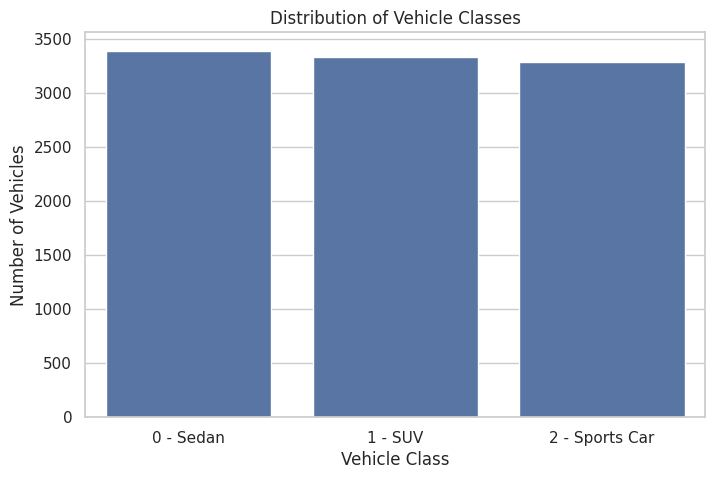

In [16]:
# ============================================
# 13. TARGET DISTRIBUTION PLOT
# ============================================

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train_df,
    x="vehicle_class"
)

plt.title("Distribution of Vehicle Classes")
plt.xlabel("Vehicle Class")
plt.ylabel("Number of Vehicles")

ax.set_xticklabels([
    "0 - Sedan",
    "1 - SUV",
    "2 - Sports Car"
])

plt.show()

In [17]:
# ============================================
# 14. NUMERICAL FEATURES
# ============================================

numerical_features = [
    col for col in train_df.columns
    if col not in ["vehicle_id", "vehicle_class"]
]

print("Number of numerical features:", len(numerical_features))

print("\nNumerical features:")
for feature in numerical_features:
    print("-", feature)

Number of numerical features: 20

Numerical features:
- engine_displacement_l
- horsepower_hp
- vehicle_weight_kg
- wheelbase_mm
- vehicle_length_mm
- vehicle_width_mm
- vehicle_height_mm
- fuel_tank_capacity_l
- city_fuel_efficiency_kmpl
- highway_fuel_efficiency_kmpl
- engine_cylinders
- torque_nm
- ground_clearance_mm
- turning_radius_m
- cargo_capacity_l
- acceleration_0_100_kmh_s
- braking_distance_m
- tire_width_mm
- drag_coefficient
- battery_capacity_kwh


In [18]:
# ============================================
# 15. DESCRIPTIVE STATISTICS
# ============================================

display(
    train_df[numerical_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,2.425913,0.614435,0.90,2.0000,2.43,2.85,4.44
horsepower_hp,10000.0,296.495000,95.563811,90.00,226.0000,294.00,364.00,550.00
vehicle_weight_kg,10000.0,1636.399900,306.182383,1100.00,1409.0000,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.057600,172.346621,2400.00,2651.0000,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.038600,366.060305,3900.00,4387.7500,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.671100,117.744583,1650.00,1744.0000,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.945000,145.978909,1250.00,1423.0000,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,61.096000,14.511383,35.00,50.0000,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.612495,2.565865,7.00,9.7500,11.56,13.36,20.87
highway_fuel_efficiency_kmpl,10000.0,15.851152,2.501685,9.00,14.1600,15.83,17.55,24.07


In [19]:
# ============================================
# 16. DETAILED NUMERICAL SUMMARY
# ============================================

summary = train_df[numerical_features].describe().T

summary["missing"] = train_df[numerical_features].isnull().sum()

summary["unique"] = train_df[numerical_features].nunique()

summary = summary[
    [
        "count",
        "missing",
        "unique",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max"
    ]
]

display(summary.round(2))

,count,missing,unique,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,0,329,2.43,0.61,0.90,2.00,2.43,2.85,4.44
horsepower_hp,10000.0,0,451,296.50,95.56,90.00,226.00,294.00,364.00,550.00
vehicle_weight_kg,10000.0,0,1271,1636.40,306.18,1100.00,1409.00,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,0,806,2778.06,172.35,2400.00,2651.00,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,0,1418,4660.04,366.06,3900.00,4387.75,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,0,401,1836.67,117.74,1650.00,1744.00,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,0,663,1528.94,145.98,1250.00,1423.00,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,0,56,61.10,14.51,35.00,50.00,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,0,1083,11.61,2.57,7.00,9.75,11.56,13.36,20.87
highway_fuel_efficiency_kmpl,10000.0,0,1187,15.85,2.50,9.00,14.16,15.83,17.55,24.07


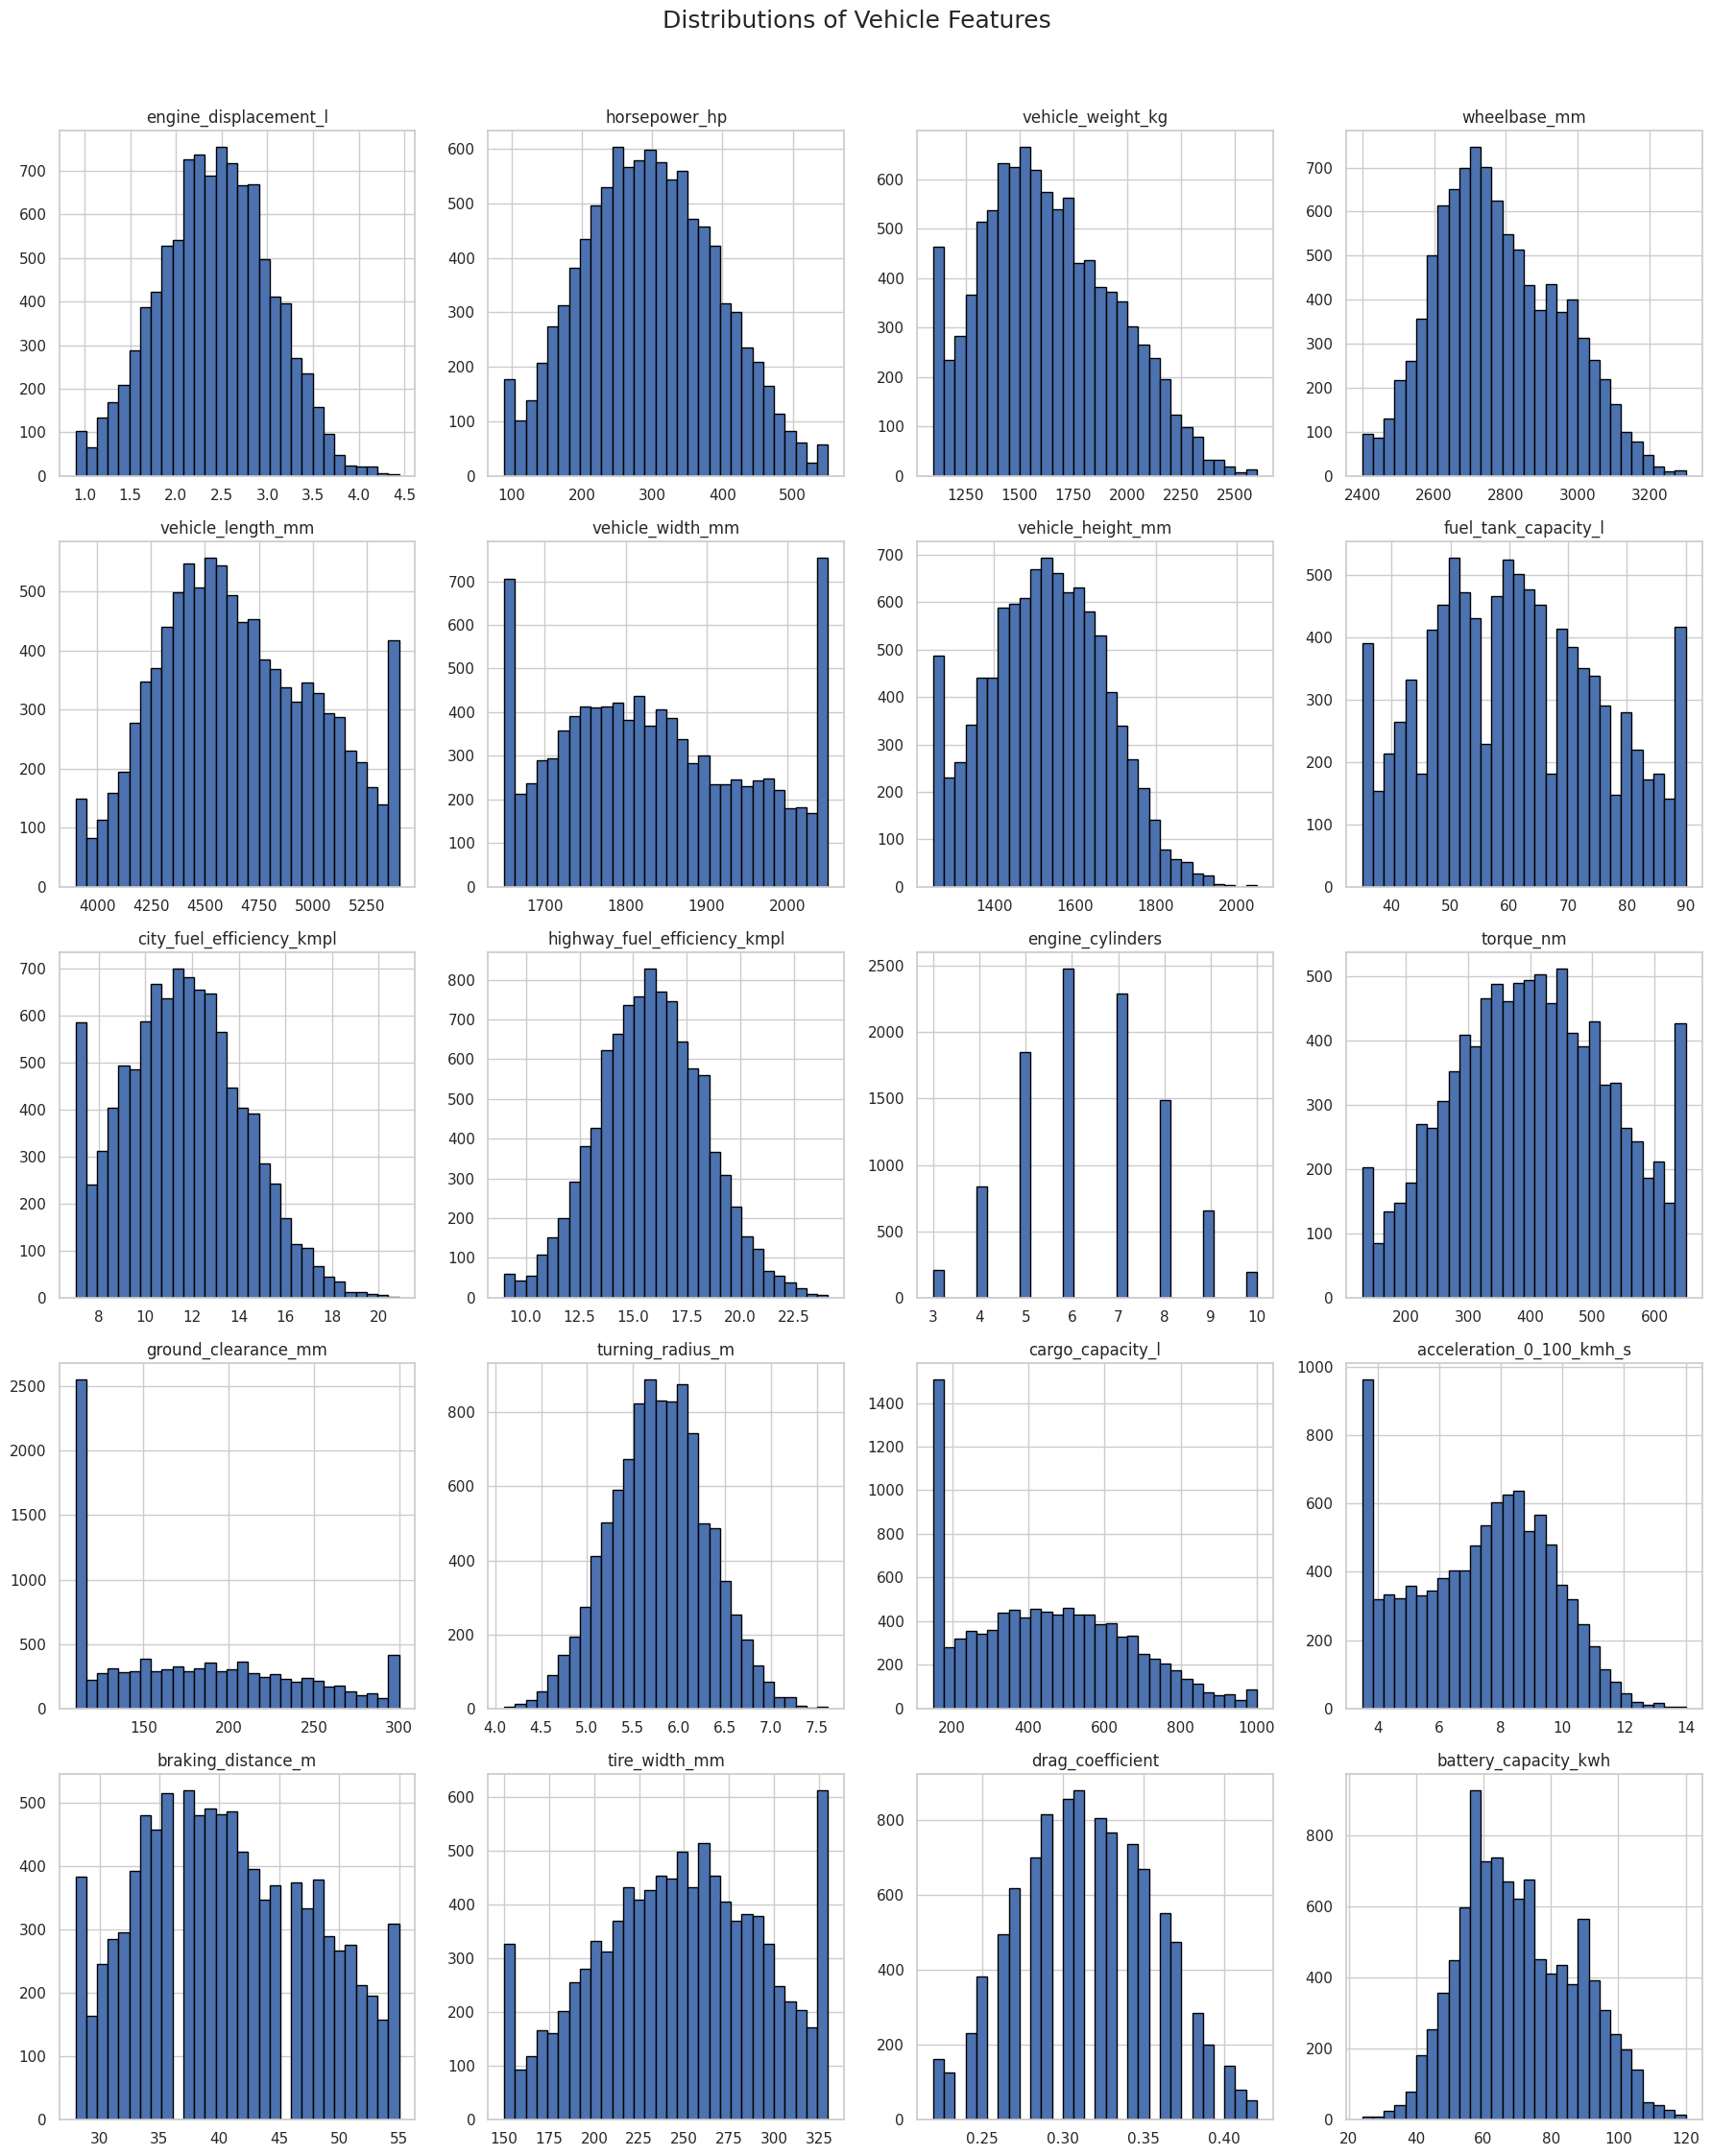

In [20]:
# ============================================
# 17. HISTOGRAMS
# ============================================

train_df[numerical_features].hist(
    figsize=(18, 22),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Vehicle Features",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

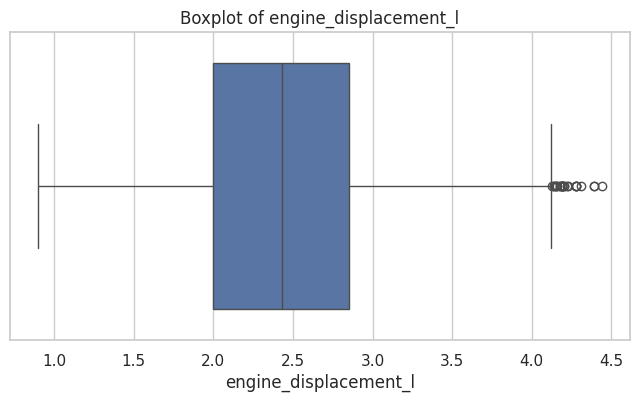

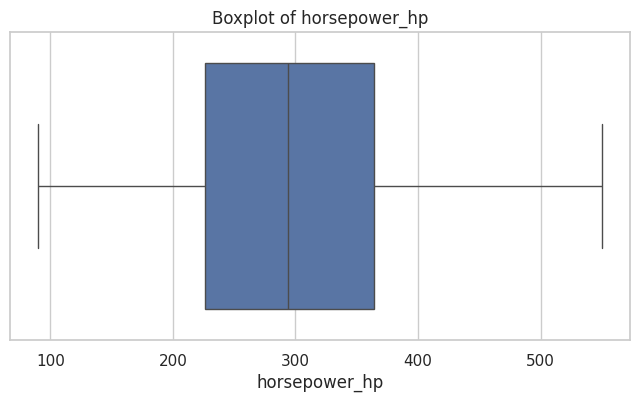

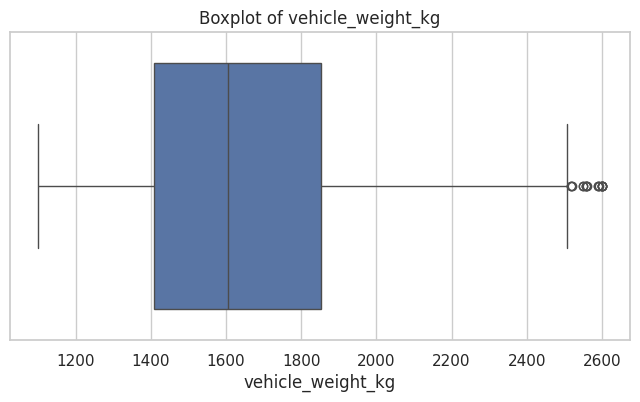

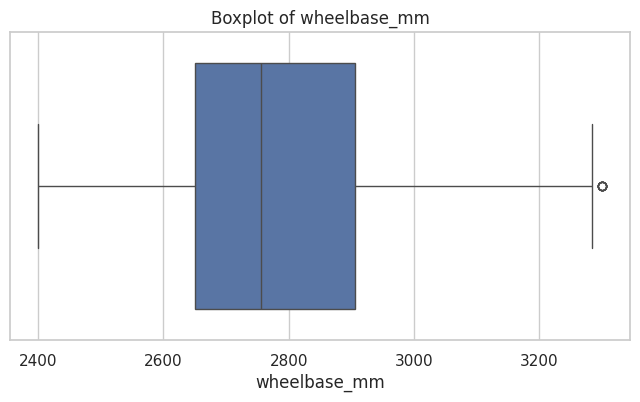

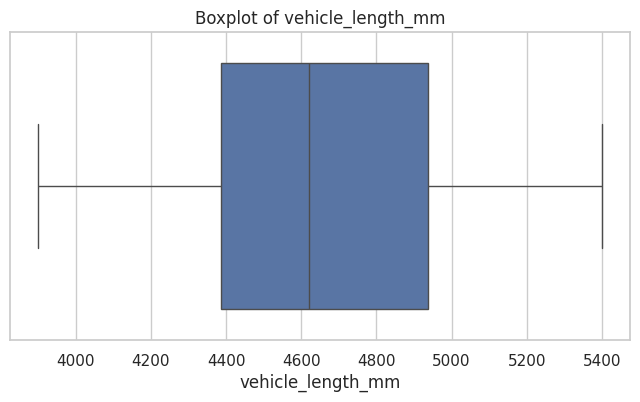

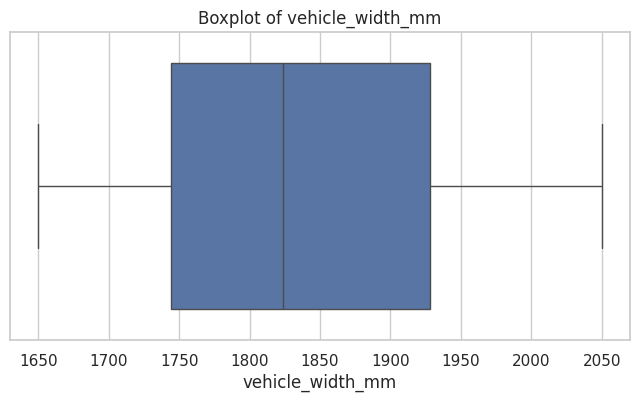

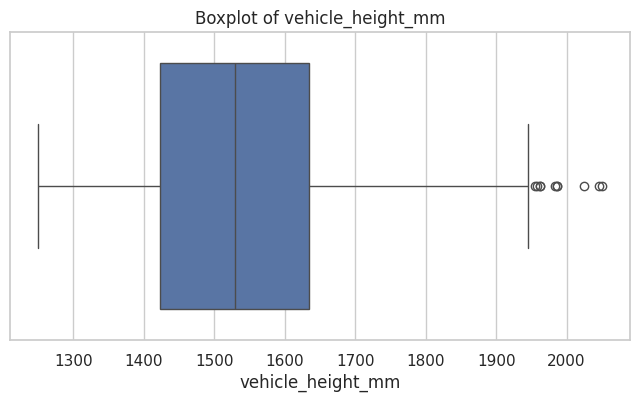

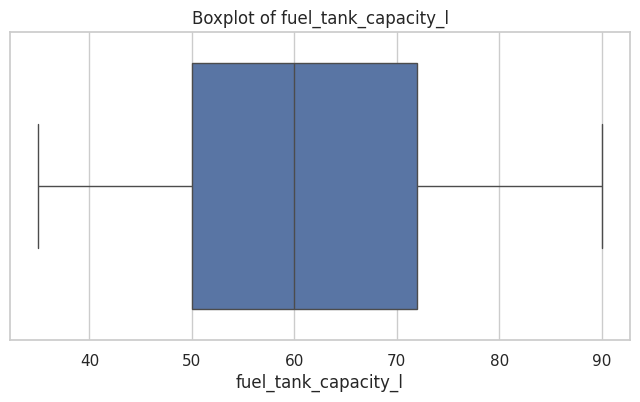

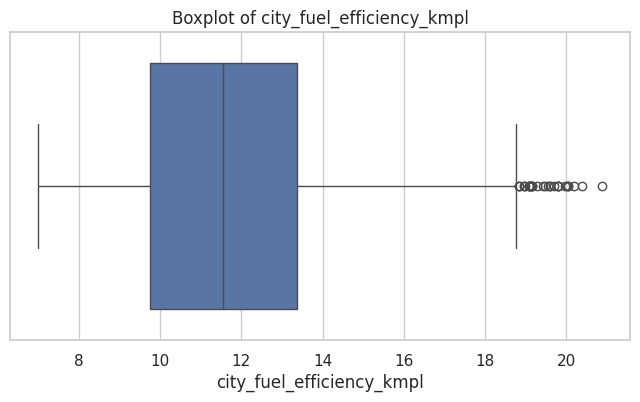

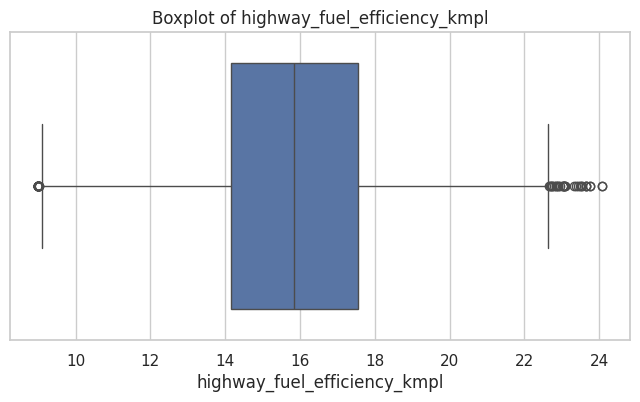

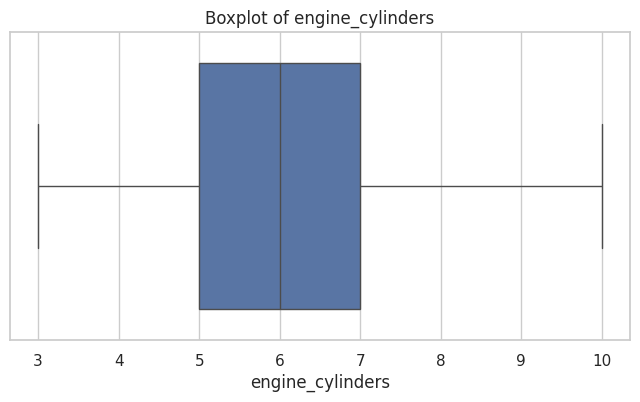

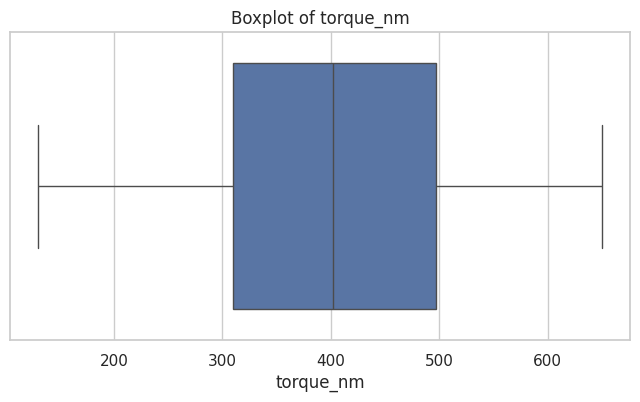

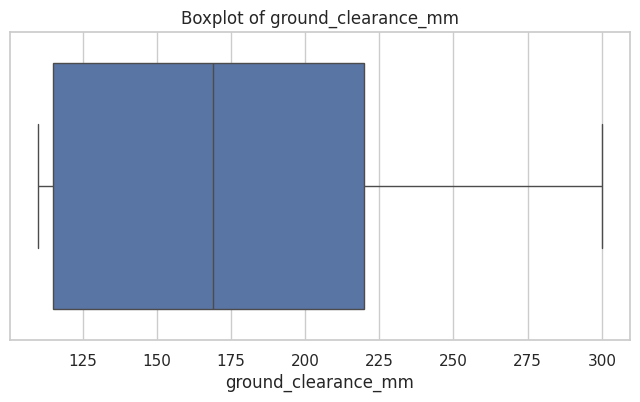

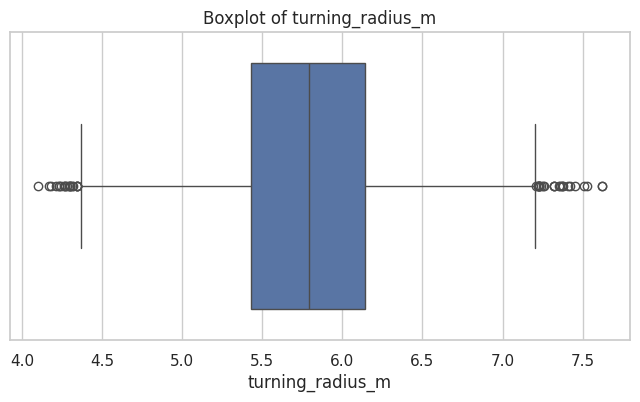

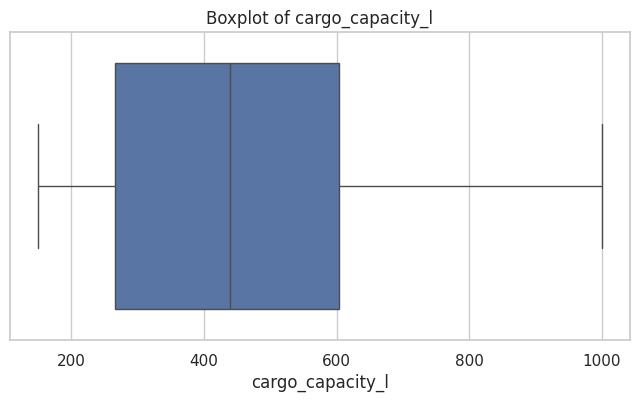

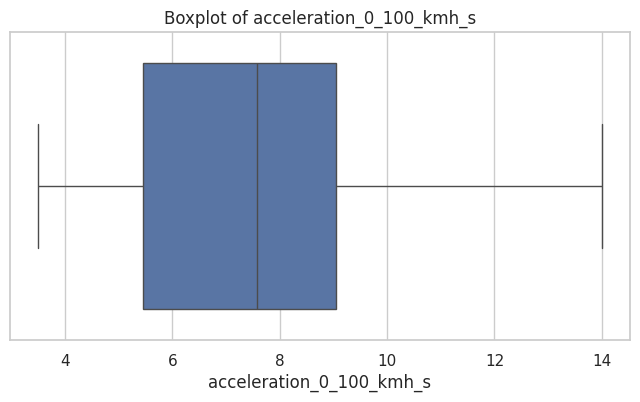

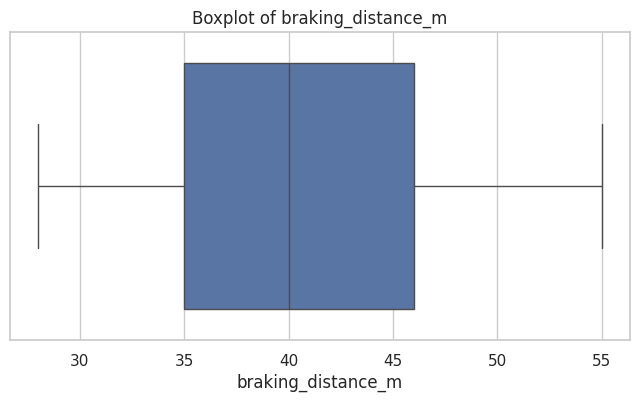

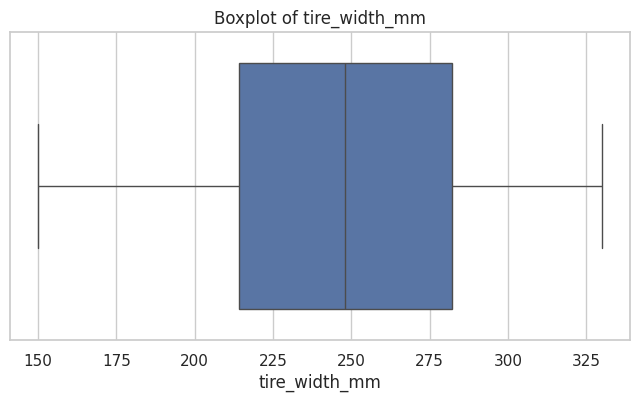

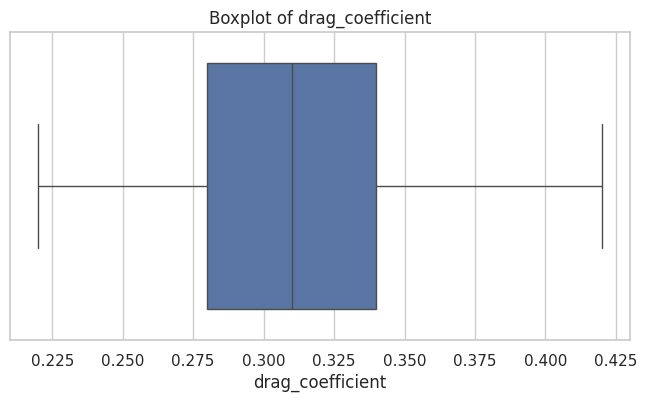

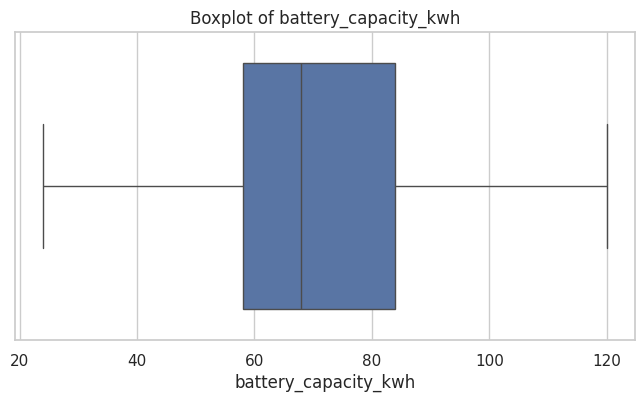

In [21]:
# ============================================
# 18. BOXPLOTS
# ============================================

for feature in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=train_df[feature]
    )

    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)

    plt.show()

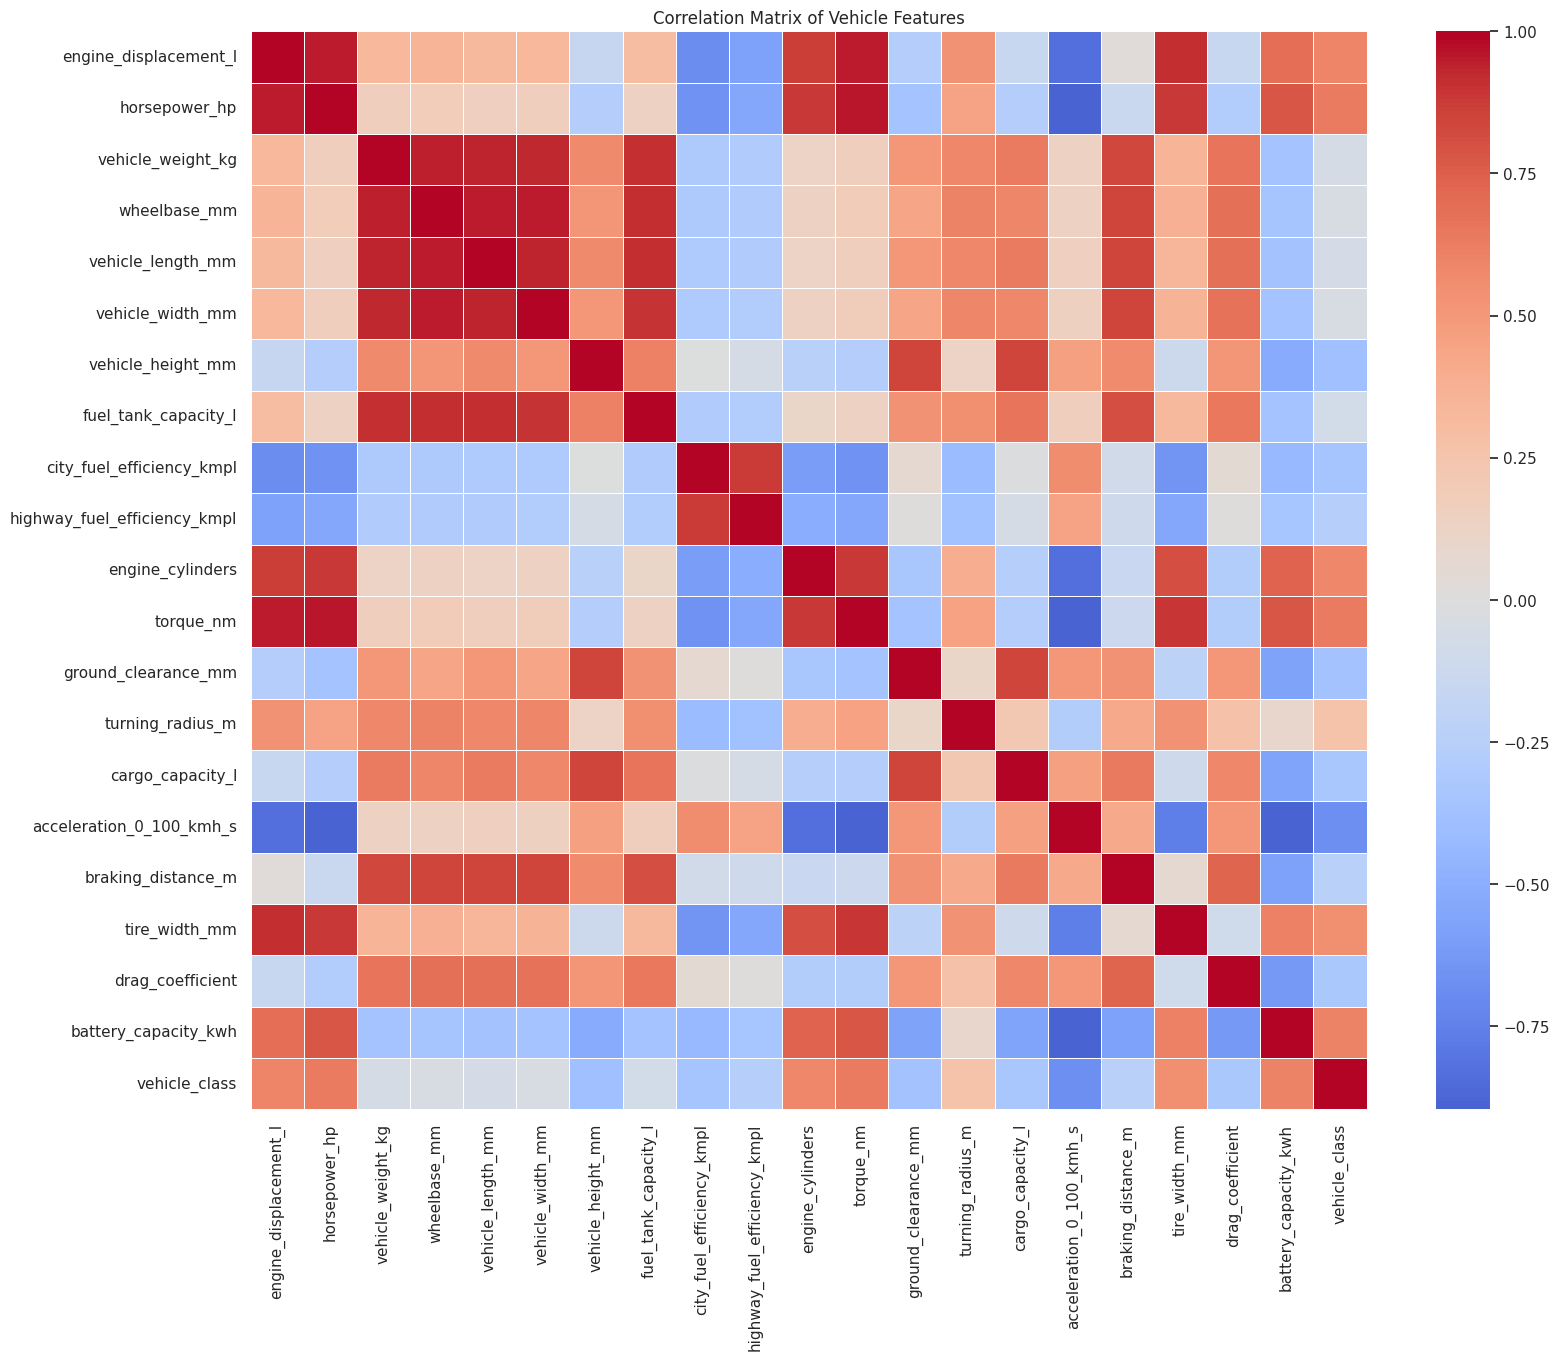

In [22]:
# ============================================
# 19. CORRELATION MATRIX
# ============================================

correlation_matrix = train_df[
    numerical_features + ["vehicle_class"]
].corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Vehicle Features")
plt.show()

In [23]:
# ============================================
# 20. HIGHLY CORRELATED FEATURE PAIRS
# ============================================

corr_matrix = train_df[numerical_features].corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs >= 0.70
]

display(
    high_corr_pairs.to_frame("Absolute Correlation")
)

Absolute Correlation
horsepower_hp             torque_nm                                 0.959029
engine_displacement_l     torque_nm                                 0.952537
wheelbase_mm              vehicle_width_mm                          0.951564
engine_displacement_l     horsepower_hp                             0.950099
wheelbase_mm              vehicle_length_mm                         0.948408
vehicle_weight_kg         wheelbase_mm                              0.945055
vehicle_length_mm         vehicle_width_mm                          0.937116
vehicle_weight_kg         vehicle_length_mm                         0.934137
                          vehicle_width_mm                          0.929065
vehicle_length_mm         fuel_tank_capacity_l                      0.913764
engine_displacement_l     tire_width_mm                             0.911952
wheelbase_mm              fuel_tank_capacity_l                      0.911615
vehicle_weight_kg         fuel_tank_capacity_l                      0.906382
vehicle_width_mm          fuel_tank_capacity_l                      0.900344
torque_nm                 acceleration_0_100_kmh_s                  0.897254
acceleration_0_100_kmh_s  battery_capacity_kwh                      0.896795
horsepower_hp             acceleration_0_100_kmh_s                  0.893648
torque_nm                 tire_width_mm                             0.890185
horsepower_hp             tire_width_mm                             0.883692
                          engine_cylinders                          0.882094
engine_cylinders          torque_nm                                 0.881918
city_fuel_efficiency_kmpl highway_fuel_efficiency_kmpl              0.874871
engine_displacement_l     engine_cylinders                          0.873002
wheelbase_mm              braking_distance_m                        0.850971
vehicle_height_mm         cargo_capacity_l                          0.846177
                          ground_clearance_mm                       0.843258
vehicle_width_mm          braking_distance_m                        0.839019
ground_clearance_mm       cargo_capacity_l                          0.838861
vehicle_length_mm         braking_distance_m                        0.837430
vehicle_weight_kg         braking_distance_m                        0.831554
engine_displacement_l     acceleration_0_100_kmh_s                  0.831399
engine_cylinders          acceleration_0_100_kmh_s                  0.830947
fuel_tank_capacity_l      braking_distance_m                        0.811615
engine_cylinders          tire_width_mm                             0.809971
horsepower_hp             battery_capacity_kwh                      0.783043
torque_nm                 battery_capacity_kwh                      0.779899
acceleration_0_100_kmh_s  tire_width_mm                             0.760615
engine_cylinders          battery_capacity_kwh                      0.735373
braking_distance_m        drag_coefficient                          0.728940

In [24]:
# ============================================
# 21. FEATURE-TARGET CORRELATION
# ============================================

target_correlations = (
    train_df[
        numerical_features + ["vehicle_class"]
    ]
    .corr()["vehicle_class"]
    .drop("vehicle_class")
    .sort_values()
)

display(
    target_correlations.to_frame(
        "Correlation with Vehicle Class"
    )
)

,Correlation with Vehicle Class
acceleration_0_100_kmh_s,-0.675236
vehicle_height_mm,-0.383202
ground_clearance_mm,-0.370372
city_fuel_efficiency_kmpl,-0.349543
cargo_capacity_l,-0.335026
drag_coefficient,-0.321175
highway_fuel_efficiency_kmpl,-0.260804
braking_distance_m,-0.245477
fuel_tank_capacity_l,-0.081850
vehicle_length_mm,-0.065047


In [25]:
print(train_df.columns.tolist())

['vehicle_id', 'engine_displacement_l', 'horsepower_hp', 'vehicle_weight_kg', 'wheelbase_mm', 'vehicle_length_mm', 'vehicle_width_mm', 'vehicle_height_mm', 'fuel_tank_capacity_l', 'city_fuel_efficiency_kmpl', 'highway_fuel_efficiency_kmpl', 'engine_cylinders', 'torque_nm', 'ground_clearance_mm', 'turning_radius_m', 'cargo_capacity_l', 'acceleration_0_100_kmh_s', 'braking_distance_m', 'tire_width_mm', 'drag_coefficient', 'battery_capacity_kwh', 'vehicle_class']


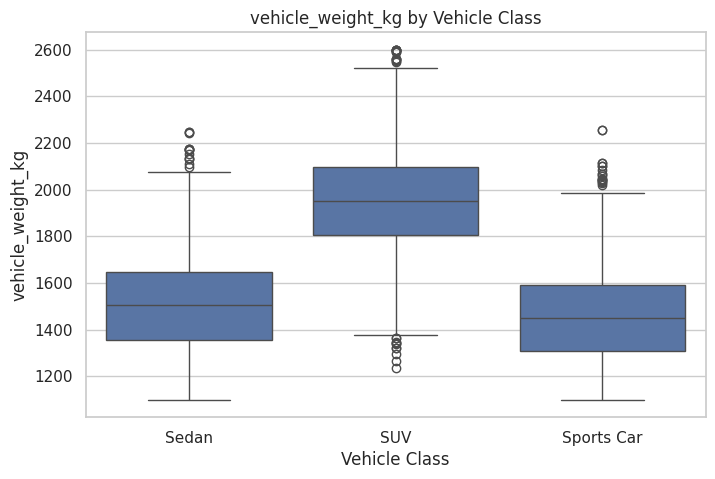

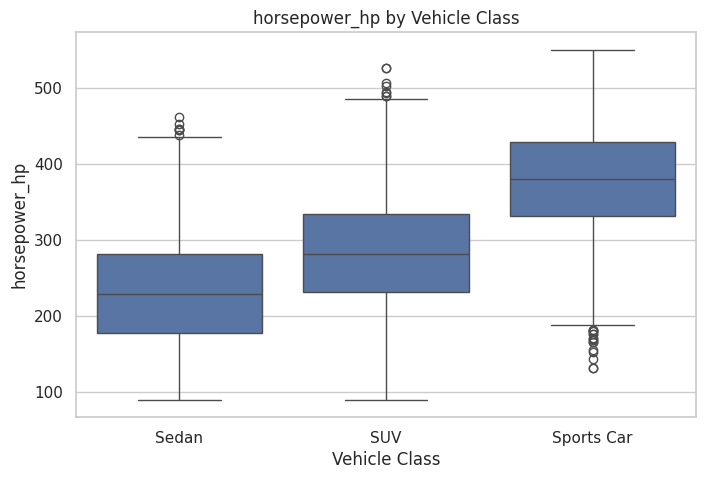

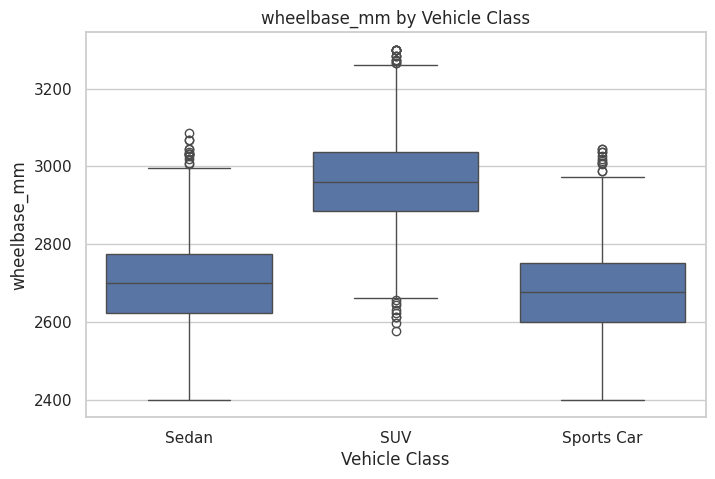

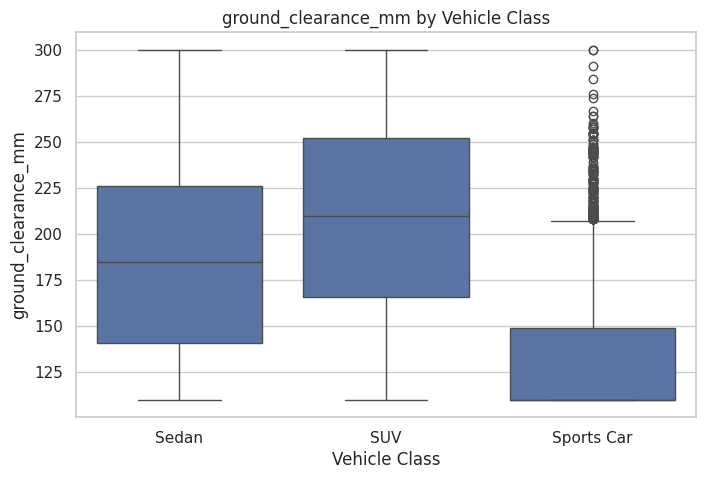

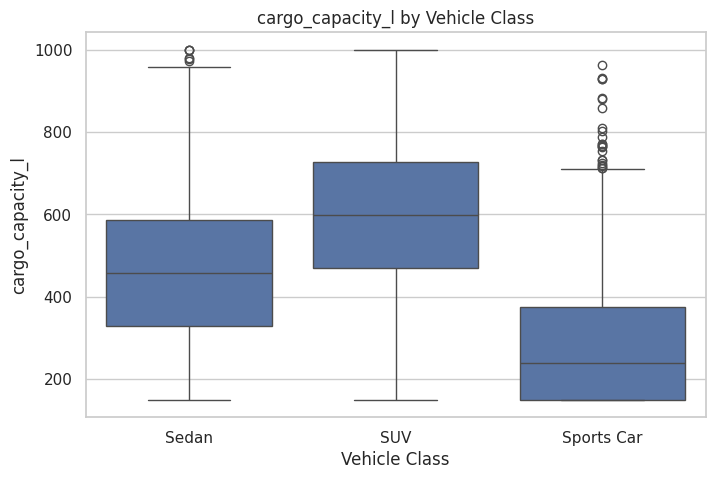

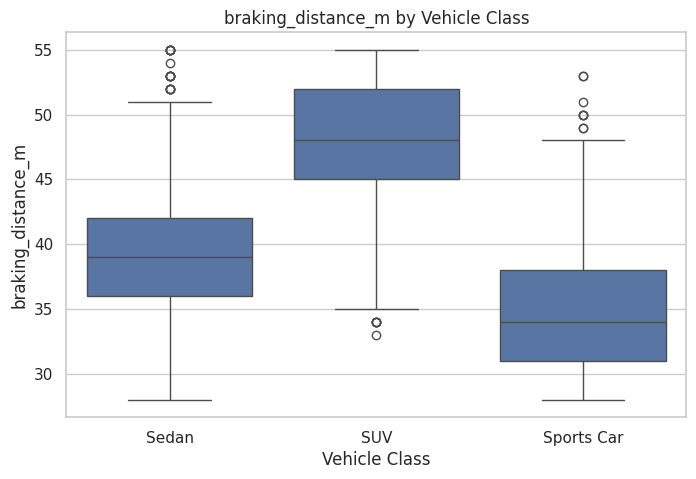

In [26]:
# ============================================
# 22. FEATURE DISTRIBUTIONS BY VEHICLE CLASS
# ============================================

important_features = [
    "vehicle_weight_kg",
    "horsepower_hp",
    "wheelbase_mm",
    "ground_clearance_mm",
    "cargo_capacity_l",
    "braking_distance_m"
]

for feature in important_features:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train_df,
        x="vehicle_class",
        y=feature
    )

    plt.title(f"{feature} by Vehicle Class")
    plt.xlabel("Vehicle Class")
    plt.ylabel(feature)

    plt.xticks(
        [0, 1, 2],
        ["Sedan", "SUV", "Sports Car"]
    )

    plt.show()

In [27]:
# ============================================
# 23. FEATURE MEANS BY VEHICLE CLASS
# ============================================

class_means = (
    train_df
    .groupby("vehicle_class")[numerical_features]
    .mean()
    .T
)

class_means.columns = [
    "Sedan",
    "SUV",
    "Sports Car"
]

display(class_means.round(2))

,Sedan,SUV,Sports Car
engine_displacement_l,1.97,2.45,2.87
horsepower_hp,230.57,282.25,378.93
vehicle_weight_kg,1503.65,1950.93,1454.89
wheelbase_mm,2697.35,2961.24,2675.86
vehicle_length_mm,4501.85,5040.89,4437.63
vehicle_width_mm,1780.76,1962.70,1766.75
vehicle_height_mm,1556.07,1611.06,1417.83
fuel_tank_capacity_l,55.49,75.44,52.36
city_fuel_efficiency_kmpl,12.88,11.23,10.69
highway_fuel_efficiency_kmpl,16.84,15.44,15.25


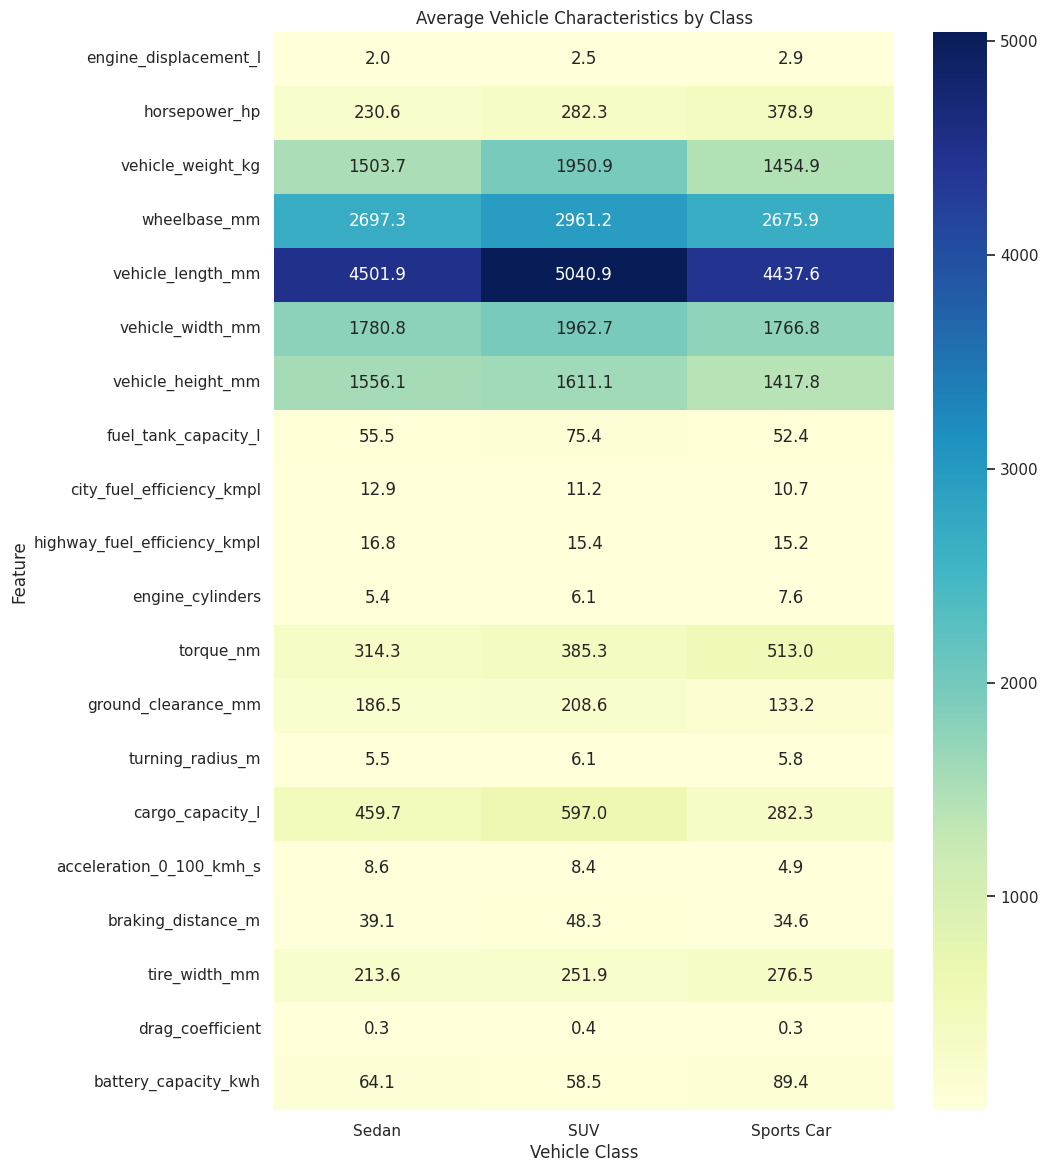

In [28]:
# ============================================
# 24. CLASS-WISE MEAN HEATMAP
# ============================================

plt.figure(figsize=(10, 14))

sns.heatmap(
    class_means,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Average Vehicle Characteristics by Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Feature")

plt.show()

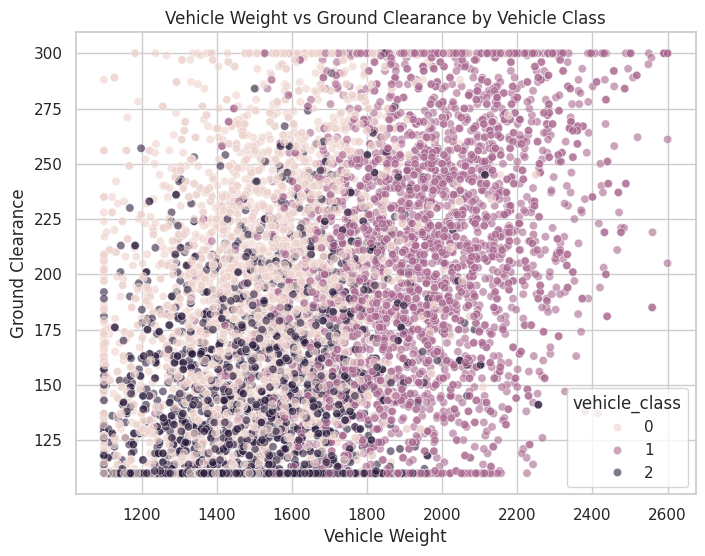

In [29]:
# ============================================
# 26. SCATTER PLOTS
# ============================================

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=train_df,
    x="vehicle_weight_kg",
    y="ground_clearance_mm",
    hue="vehicle_class",
    alpha=0.6
)

plt.title(
    "Vehicle Weight vs Ground Clearance by Vehicle Class"
)

plt.xlabel("Vehicle Weight")
plt.ylabel("Ground Clearance")

plt.show()

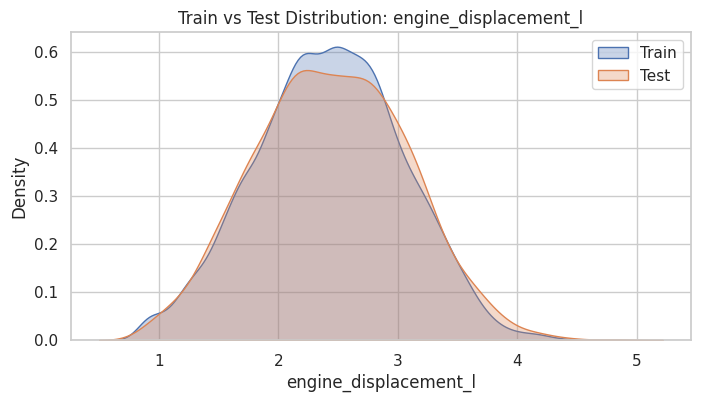

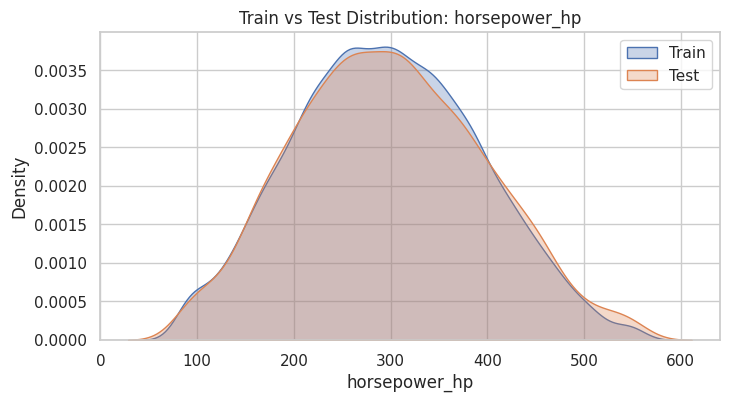

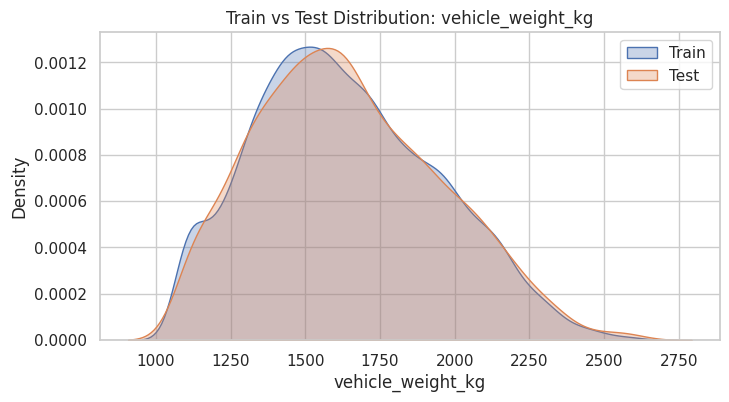

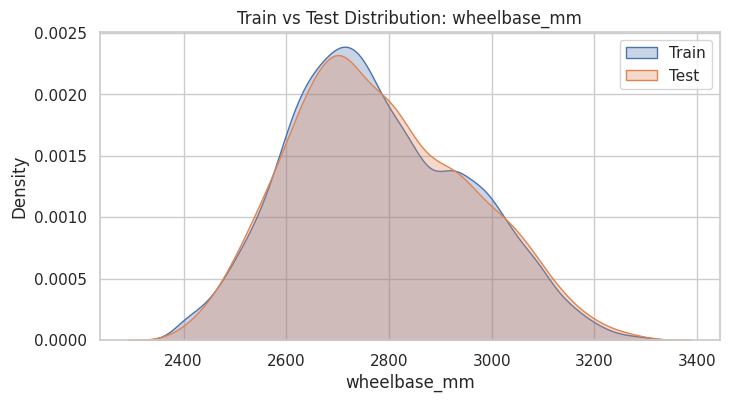

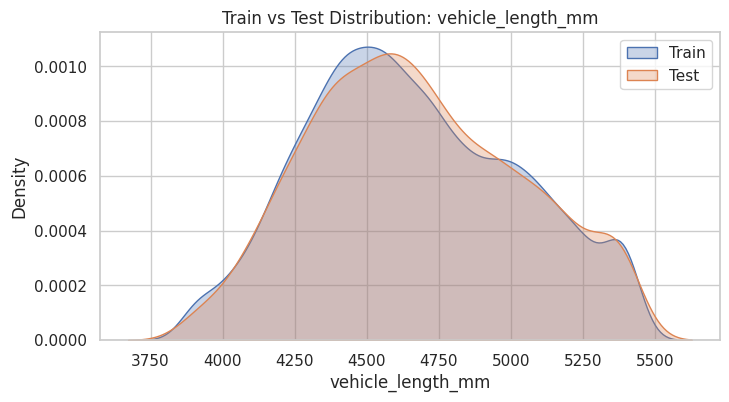

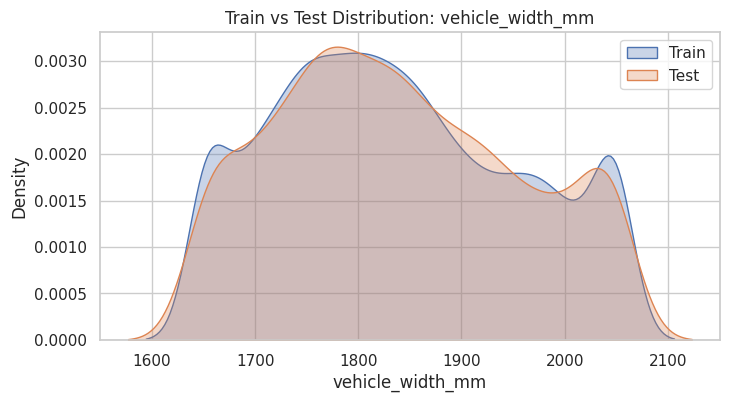

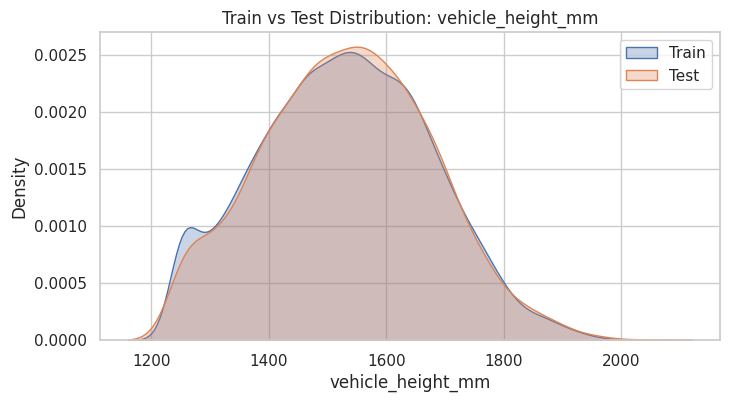

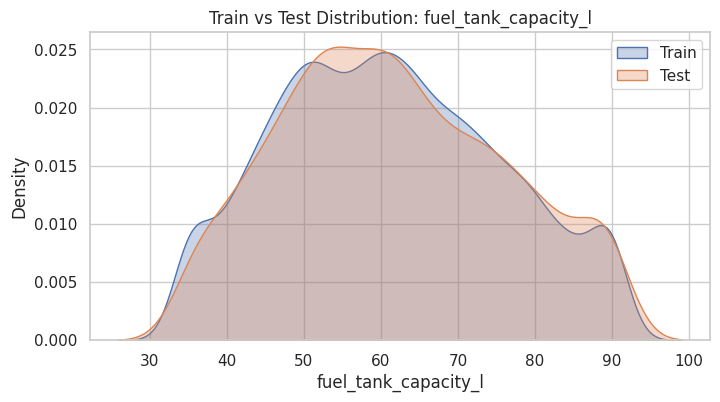

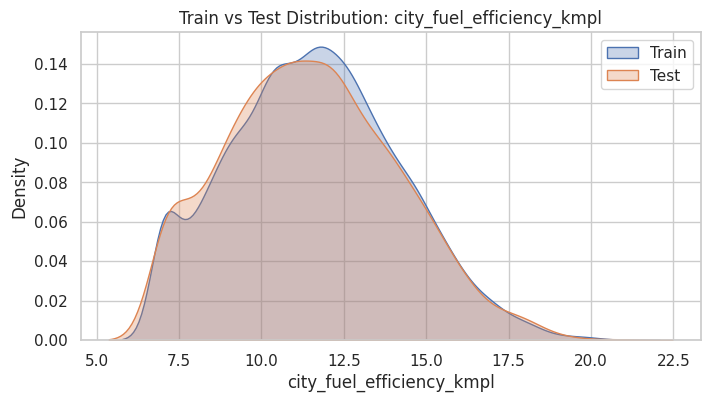

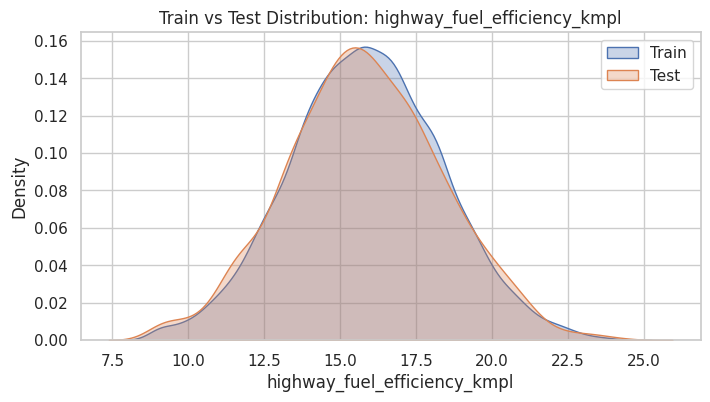

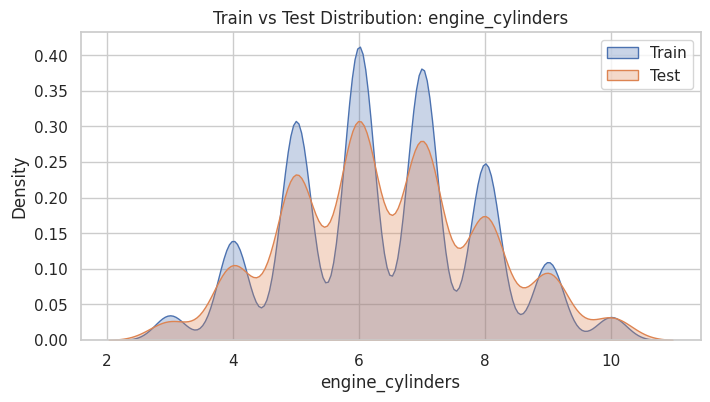

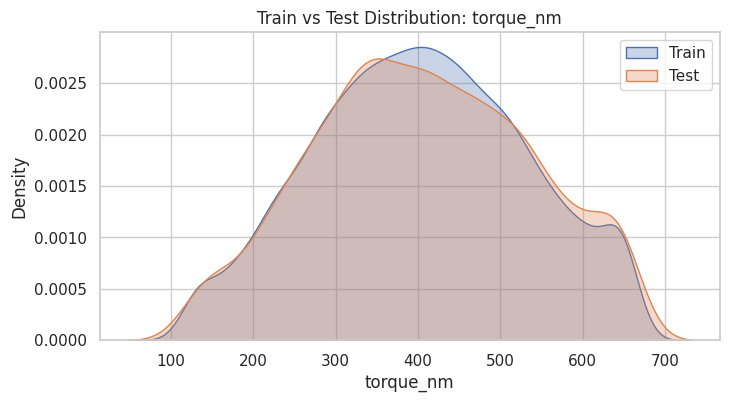

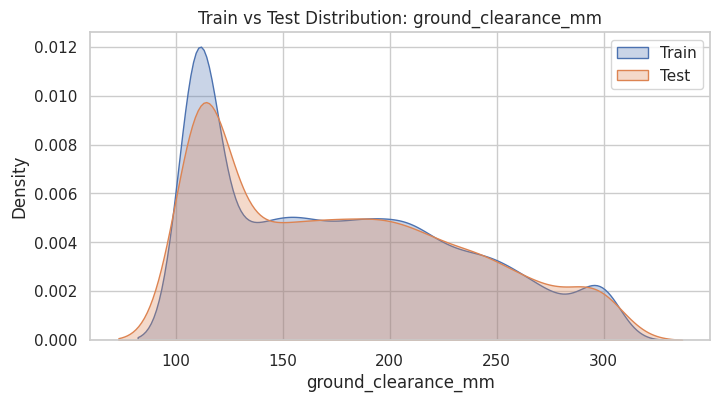

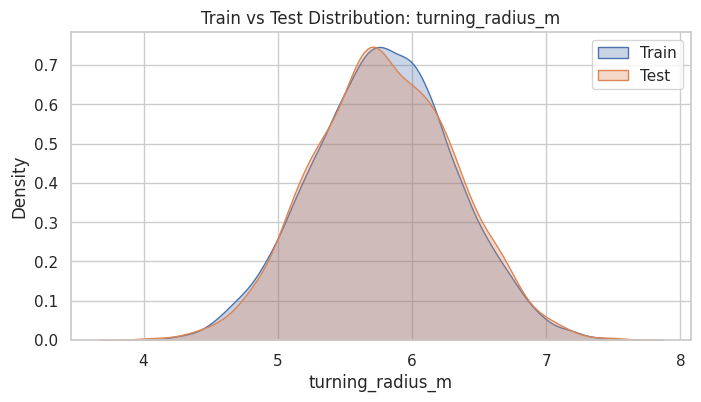

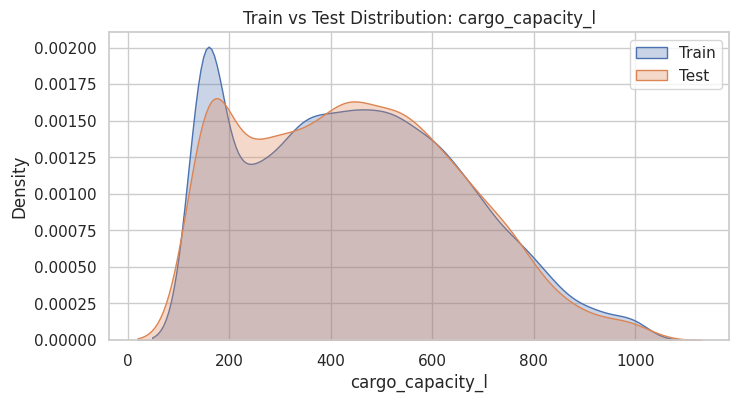

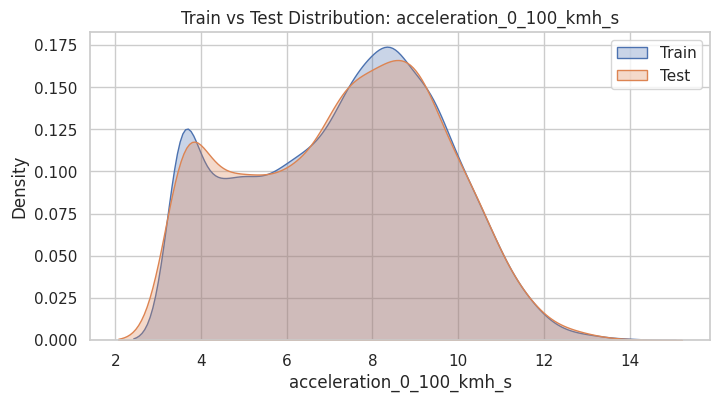

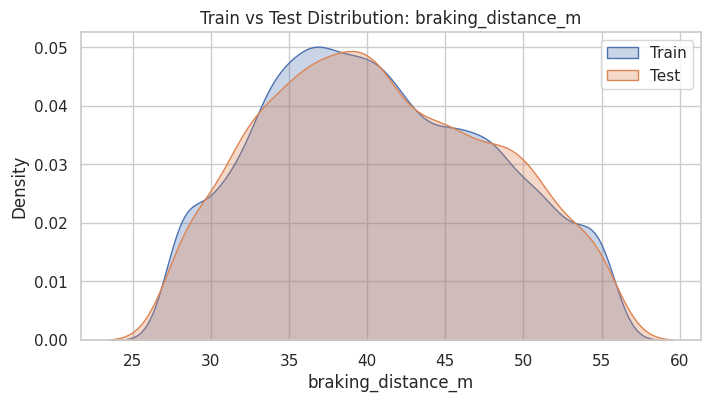

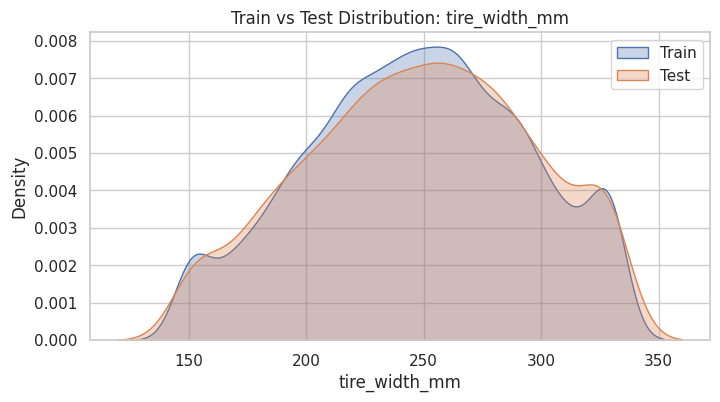

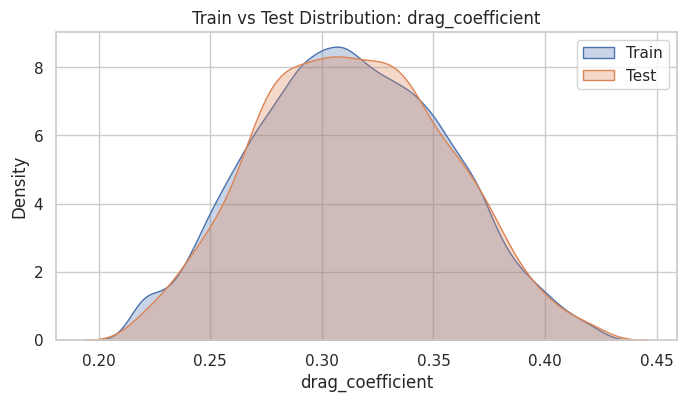

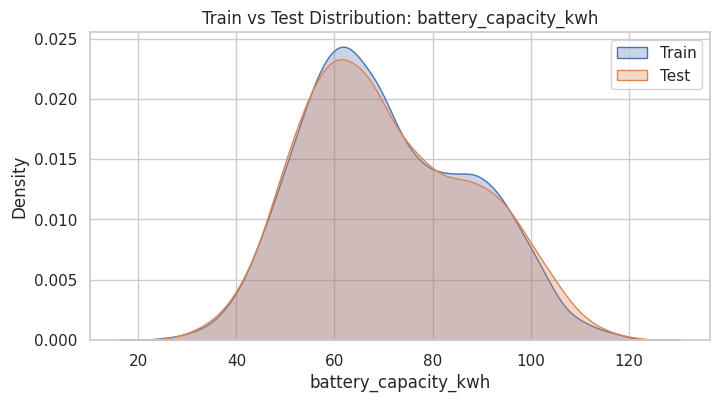

In [30]:
# ============================================
# 27. TRAIN VS TEST FEATURE DISTRIBUTION
# ============================================

for feature in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.kdeplot(
        train_df[feature],
        label="Train",
        fill=True,
        alpha=0.3
    )

    sns.kdeplot(
        test_df[feature],
        label="Test",
        fill=True,
        alpha=0.3
    )

    plt.title(f"Train vs Test Distribution: {feature}")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()

    plt.show()

In [31]:
# ============================================
# 28. TRAIN VS TEST SUMMARY
# ============================================

distribution_comparison = pd.DataFrame(index=numerical_features)

distribution_comparison["Train Mean"] = (
    train_df[numerical_features].mean()
)

distribution_comparison["Test Mean"] = (
    test_df[numerical_features].mean()
)

distribution_comparison["Train Std"] = (
    train_df[numerical_features].std()
)

distribution_comparison["Test Std"] = (
    test_df[numerical_features].std()
)

distribution_comparison["Mean Difference %"] = (
    (
        distribution_comparison["Test Mean"]
        -
        distribution_comparison["Train Mean"]
    )
    /
    distribution_comparison["Train Mean"].replace(0, np.nan)
    * 100
)

display(
    distribution_comparison.round(2)
)

,Train Mean,Test Mean,Train Std,Test Std,Mean Difference %
engine_displacement_l,2.43,2.44,0.61,0.63,0.74
horsepower_hp,296.50,298.80,95.56,97.97,0.78
vehicle_weight_kg,1636.40,1643.93,306.18,308.29,0.46
wheelbase_mm,2778.06,2782.58,172.35,172.93,0.16
vehicle_length_mm,4660.04,4670.62,366.06,363.34,0.23
vehicle_width_mm,1836.67,1838.50,117.74,116.56,0.10
vehicle_height_mm,1528.94,1532.26,145.98,143.50,0.22
fuel_tank_capacity_l,61.10,61.58,14.51,14.49,0.79
city_fuel_efficiency_kmpl,11.61,11.51,2.57,2.60,-0.92
highway_fuel_efficiency_kmpl,15.85,15.79,2.50,2.58,-0.40


In [32]:
# ============================================
# 29. CHECK SUBMISSION FORMAT
# ============================================

print("Sample submission columns:")
print(sample_submission.columns.tolist())

print("\nSample submission shape:")
print(sample_submission.shape)

display(sample_submission.head())

Sample submission columns:
['vehicle_id', 'vehicle_class']

Sample submission shape:
(2500, 2)


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,0
3,10004,0
4,10005,0


In [33]:
# ============================================
# 30. IMPORTS AND FEATURE SETUP
# ============================================
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
TARGET = "vehicle_class"
ID_COL = "vehicle_id"

feature_columns = [c for c in train_df.columns if c not in [ID_COL, TARGET]]
X = train_df[feature_columns].copy()
y = train_df[TARGET].astype(int).copy()
X_test = test_df[feature_columns].copy()

print("Features used:", len(feature_columns))
print("Training rows:", len(X), "| Test rows:", len(X_test))
print("Class distribution:\n", y.value_counts(normalize=True).sort_index().round(4))

Features used: 20
Training rows: 10000 | Test rows: 2500
Class distribution:
 vehicle_class
0    0.3389
1    0.3326
2    0.3285
Name: proportion, dtype: float64


In [34]:
# ============================================
# 31. FEATURE ENGINEERING FOR LOGISTIC REGRESSION
# ============================================
def engineer_lr_features(frame):
    d = frame.copy()
    d["power_to_weight"] = d["horsepower_hp"] / d["vehicle_weight_kg"].clip(lower=1)
    d["torque_to_weight"] = d["torque_nm"] / d["vehicle_weight_kg"].clip(lower=1)
    d["wheelbase_to_length"] = d["wheelbase_mm"] / d["vehicle_length_mm"].clip(lower=1)
    d["width_to_height"] = d["vehicle_width_mm"] / d["vehicle_height_mm"].clip(lower=1)
    d["length_to_width"] = d["vehicle_length_mm"] / d["vehicle_width_mm"].clip(lower=1)
    d["cargo_to_weight"] = d["cargo_capacity_l"] / d["vehicle_weight_kg"].clip(lower=1)
    d["fuel_efficiency_gap"] = d["highway_fuel_efficiency_kmpl"] - d["city_fuel_efficiency_kmpl"]
    d["horsepower_per_cylinder"] = d["horsepower_hp"] / d["engine_cylinders"].clip(lower=1)
    d["tire_to_width"] = d["tire_width_mm"] / d["vehicle_width_mm"].clip(lower=1)
    return d.replace([np.inf, -np.inf], np.nan)

X_lr = engineer_lr_features(X)
X_test_lr = engineer_lr_features(X_test)
print("Original feature count:", X.shape[1], "| Engineered LR feature count:", X_lr.shape[1])

Original feature count: 20 | Engineered LR feature count: 29


In [35]:
# ============================================
# 32. DUPLICATE-AWARE GROUPS
# ============================================
# Rows with identical original feature values stay together in each fold.
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
group_info = pd.DataFrame({"group": groups, "target": y.to_numpy()})
conflicts = int(group_info.groupby("group")["target"].nunique().gt(1).sum())
print("Unique original feature groups:", pd.Series(groups).nunique())
print("Rows belonging to duplicate feature groups:",
      int(pd.Series(groups).duplicated(keep=False).sum()))
print("Duplicate groups with conflicting labels:", conflicts)
if conflicts:
    raise ValueError("Identical feature rows have conflicting labels; inspect before training.")

Unique original feature groups: 7500
Rows belonging to duplicate feature groups: 5000
Duplicate groups with conflicting labels: 0


In [36]:
# ============================================
# 33. GROUPED 5-FOLD CROSS-VALIDATION
# ============================================
# Every candidate uses the same folds for a fair comparison.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Engineered Logistic Regression": (
        X_lr,
        make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOM_STATE)
        )
    ),
    "Linear Discriminant Analysis": (
        X,
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LinearDiscriminantAnalysis())
    ),
    "RBF SVM": (
        X,
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      SVC(C=3.0, kernel="rbf", gamma="scale", probability=True,
                          random_state=RANDOM_STATE))
    ),
    "Random Forest": (
        X,
        RandomForestClassifier(n_estimators=300, max_features="sqrt",
                               min_samples_leaf=1, n_jobs=-1,
                               random_state=RANDOM_STATE)
    )
}

cv_rows = []
oof_probabilities = {}
classes = np.sort(y.unique())
for name, (features, estimator) in models.items():
    oof = np.zeros((len(X), len(classes)), dtype=float)
    fold_scores = []
    for fold, (tr_idx, va_idx) in enumerate(cv.split(features, y, groups), start=1):
        model = clone(estimator)
        model.fit(features.iloc[tr_idx], y.iloc[tr_idx])
        pred = np.asarray(model.predict(features.iloc[va_idx])).reshape(-1).astype(int)
        score = accuracy_score(y.iloc[va_idx], pred)
        fold_scores.append(score)
        if hasattr(model, "predict_proba"):
            raw_probs = model.predict_proba(features.iloc[va_idx])
            model_classes = model.classes_ if hasattr(model, "classes_") else model[-1].classes_
            for j, cls in enumerate(model_classes):
                oof[va_idx, np.where(classes == cls)[0][0]] = raw_probs[:, j]
        print(f"{name} | fold {fold}: accuracy={score:.4f}")
    oof_probabilities[name] = oof
    cv_rows.append({
        "Model": name,
        "Mean grouped CV accuracy": float(np.mean(fold_scores)),
        "Std grouped CV accuracy": float(np.std(fold_scores)),
        "Fold scores": np.round(fold_scores, 4).tolist()
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values(
    "Mean grouped CV accuracy", ascending=False
).reset_index(drop=True)
display(cv_results_df)

Engineered Logistic Regression | fold 1: accuracy=0.8974
Engineered Logistic Regression | fold 2: accuracy=0.8959
Engineered Logistic Regression | fold 3: accuracy=0.8970
Engineered Logistic Regression | fold 4: accuracy=0.8864
Engineered Logistic Regression | fold 5: accuracy=0.8879
Linear Discriminant Analysis | fold 1: accuracy=0.8969
Linear Discriminant Analysis | fold 2: accuracy=0.8994
Linear Discriminant Analysis | fold 3: accuracy=0.8960
Linear Discriminant Analysis | fold 4: accuracy=0.8829
Linear Discriminant Analysis | fold 5: accuracy=0.8904
RBF SVM | fold 1: accuracy=0.8999
RBF SVM | fold 2: accuracy=0.8904
RBF SVM | fold 3: accuracy=0.8955
RBF SVM | fold 4: accuracy=0.8788
RBF SVM | fold 5: accuracy=0.8845
Random Forest | fold 1: accuracy=0.8889
Random Forest | fold 2: accuracy=0.8794
Random Forest | fold 3: accuracy=0.8960
Random Forest | fold 4: accuracy=0.8738
Random Forest | fold 5: accuracy=0.8815


,Model,Mean grouped CV accuracy,Std grouped CV accuracy,Fold scores
0,Linear Discriminant Analysis,0.893106,0.005918,"[0.8969, 0.8994, 0.896, 0.8829, 0.8904]"
1,Engineered Logistic Regression,0.892919,0.004770,"[0.8974, 0.8959, 0.897, 0.8864, 0.8879]"
2,RBF SVM,0.889823,0.007541,"[0.8999, 0.8904, 0.8955, 0.8788, 0.8845]"
3,Random Forest,0.883914,0.007731,"[0.8889, 0.8794, 0.896, 0.8738, 0.8815]"


In [37]:
# ============================================
# 34. CHECK A SIMPLE PROBABILITY BLEND
# ============================================
# This blend was checked using out-of-fold probabilities only.
lr_oof = oof_probabilities["Engineered Logistic Regression"]
lda_oof = oof_probabilities["Linear Discriminant Analysis"]
lr_oof_accuracy = accuracy_score(y, classes[lr_oof.argmax(axis=1)])
lda_oof_accuracy = accuracy_score(y, classes[lda_oof.argmax(axis=1)])
blend_oof = 0.5 * lr_oof + 0.5 * lda_oof
blend_oof_accuracy = accuracy_score(y, classes[blend_oof.argmax(axis=1)])

print(f"LR out-of-fold accuracy: {lr_oof_accuracy:.4f}")
print(f"LDA out-of-fold accuracy: {lda_oof_accuracy:.4f}")
print(f"50/50 LR + LDA out-of-fold accuracy: {blend_oof_accuracy:.4f}")
print("Use these as estimates, not a guarantee of Kaggle test accuracy.")

LR out-of-fold accuracy: 0.8929
LDA out-of-fold accuracy: 0.8931
50/50 LR + LDA out-of-fold accuracy: 0.8935
Use these as estimates, not a guarantee of Kaggle test accuracy.


In [38]:
# ============================================
# 35. FIT FINAL MODELS ON ALL LABELED DATA
# ============================================
# These models are fixed based on cross-validation, not test-set feedback.
final_lr = clone(models["Engineered Logistic Regression"][1])
final_lda = clone(models["Linear Discriminant Analysis"][1])

final_lr.fit(X_lr, y)
final_lda.fit(X, y)

lr_test_prob = final_lr.predict_proba(X_test_lr)
lda_test_prob = final_lda.predict_proba(X_test)

# Align probability columns to the same class order before averaging.
lr_classes = final_lr[-1].classes_
lda_classes = final_lda[-1].classes_
lda_aligned = np.zeros_like(lr_test_prob)
for j, cls in enumerate(lda_classes):
    lda_aligned[:, np.where(lr_classes == cls)[0][0]] = lda_test_prob[:, j]

test_prob = 0.5 * lr_test_prob + 0.5 * lda_aligned
test_predictions = lr_classes[test_prob.argmax(axis=1)].astype(int)
print("Prediction count:", len(test_predictions))
print("Predicted class counts:", pd.Series(test_predictions).value_counts().sort_index().to_dict())

Prediction count: 2500
Predicted class counts: {0: 829, 1: 841, 2: 830}


In [39]:
# ============================================
# 36. WRITE result.csv
# ============================================
submission = sample_submission.copy()
prediction_map = pd.Series(test_predictions, index=test_df[ID_COL])
submission[TARGET] = submission[ID_COL].map(prediction_map)

assert len(submission) == len(test_df)
assert submission.columns.tolist() == sample_submission.columns.tolist()
assert submission[ID_COL].is_unique
assert submission[TARGET].notna().all()
submission[TARGET] = submission[TARGET].astype(int)
assert set(submission[TARGET].unique()).issubset(set(y.unique()))

# Kaggle output directory when available; otherwise the current working directory.
output_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
output_path = output_dir / "result.csv"
submission.to_csv(output_path, index=False)

check = pd.read_csv(output_path)
assert check.shape == sample_submission.shape
assert check.columns.tolist() == sample_submission.columns.tolist()
assert check.isna().sum().sum() == 0
assert check[ID_COL].is_unique
assert check[TARGET].isin(y.unique()).all()

print("Saved:", output_path)
print("Shape:", check.shape)
print("Missing values:", int(check.isna().sum().sum()))
display(check.head())

Saved: /kaggle/working/result.csv
Shape: (2500, 2)
Missing values: 0


,vehicle_id,vehicle_class
0,10001,0
1,10002,0
2,10003,1
3,10004,2
4,10005,1
